1. DATASET OVERVIEW & DESCRIPTION
Dataset Shape: 12330 rows, 18 columns

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-n

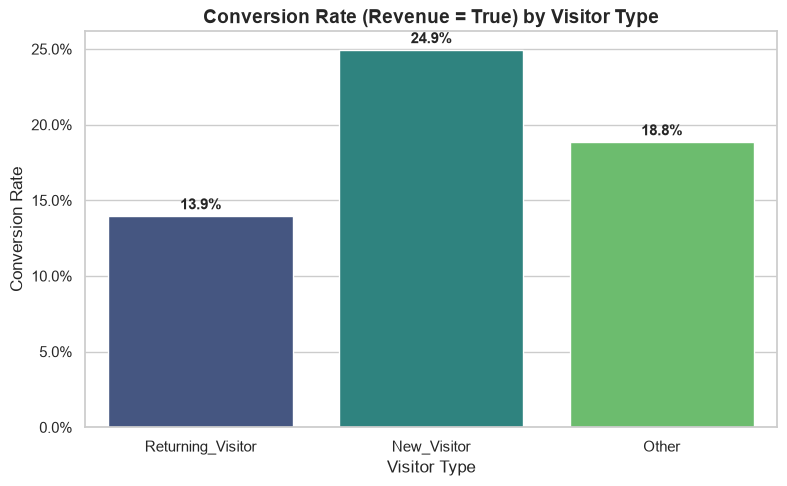

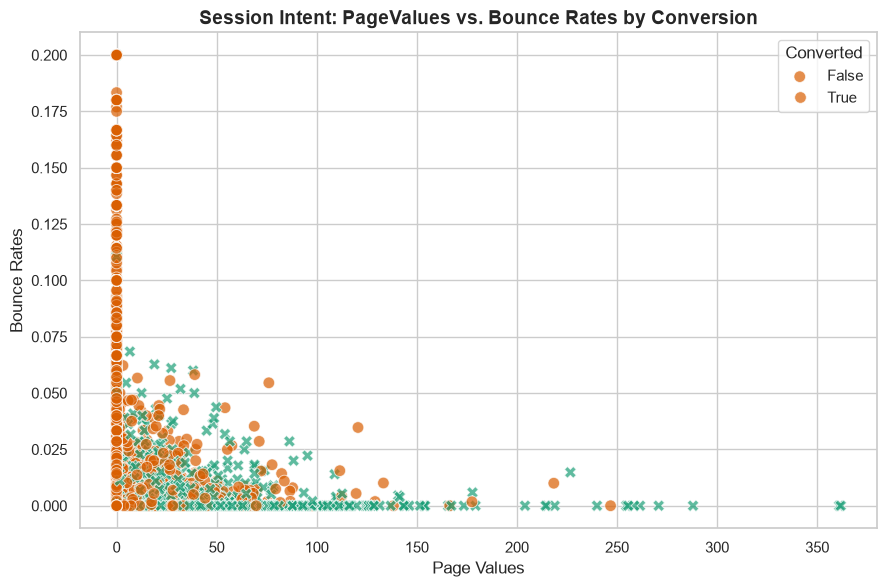


3. DATA PRE-PROCESSING
Total missing values found: 0

4. DATA SPLITTING
Total Dataset Count:      12330
Training set shape:       (8630, 23) (70.0%)
Validation set shape:     (1850, 23) (15.0%)
Test set shape:           (1850, 23) (15.0%)

Stratification Check (Positive Target Rate across splits):
 Train positive rate:      15.48%
 Validation positive rate: 15.46%
 Test positive rate:       15.46%


In [1]:
"""
E-Commerce Shoppers Intent Pipeline
Covers: Problem Statement & Data Description, EDA, Pre-processing, and Data Splitting.
Follows PEP 8 formatting standards.
"""

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set publication-quality styling for EDA visualizations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})


# ==============================================================================
# 1. DATA LOADING & DESCRIPTION
# ==============================================================================

# Load dataset (adjust path as needed)
df = pd.read_csv(r"C:\Users\tlsun\OneDrive\Desktop\USD Assignment\Applied Data Science for Business\Final Project 505\online_shoppers_intention.csv")

print("=" * 70)
print("1. DATASET OVERVIEW & DESCRIPTION")
print("=" * 70)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nData Types and Non-Null Counts:")
print(df.info())

print("\nTarget Class Distribution ('Revenue'):")
target_counts = df["Revenue"].value_counts()
target_pct = df["Revenue"].value_counts(normalize=True) * 100
for val in target_counts.index:
    print(f" Class {val}: {target_counts[val]} sessions ({target_pct[val]:.2f}%)")


# ==============================================================================
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ==============================================================================

print("\n" + "=" * 70)
print("2. EXPLORATORY DATA ANALYSIS")
print("=" * 70)

# Summary statistics for numerical metrics
print("\nNumerical Feature Summary Statistics:")
print(df.describe().T[["mean", "std", "min", "50%", "max"]])

# --- Chart 1: Conversion Rate by Visitor Type ---
fig1, ax1 = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=df,
    x="VisitorType",
    y="Revenue",
    hue="VisitorType",
    legend=False,
    errorbar=None,
    palette="viridis",
    ax=ax1,
)
ax1.set_title(
    "Conversion Rate (Revenue = True) by Visitor Type",
    fontsize=14,
    fontweight="bold",
)
ax1.set_xlabel("Visitor Type", fontsize=12)
ax1.set_ylabel("Conversion Rate", fontsize=12)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

for p in ax1.patches:
    height = p.get_height()
    if height > 0:
        ax1.annotate(
            f"{height * 100:.1f}%",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="center",
            xytext=(0, 8),
            textcoords="offset points",
            fontweight="bold",
        )
plt.show()

# --- Chart 2: Intent Signal (PageValues vs. BounceRates) ---
fig2, ax2 = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="PageValues",
    y="BounceRates",
    hue="Revenue",
    style="Revenue",
    alpha=0.7,
    s=70,
    palette={False: "#d95f02", True: "#1b9e77"},
    ax=ax2,
)
ax2.set_title(
    "Session Intent: PageValues vs. Bounce Rates by Conversion",
    fontsize=14,
    fontweight="bold",
)
ax2.set_xlabel("Page Values", fontsize=12)
ax2.set_ylabel("Bounce Rates", fontsize=12)
plt.legend(title="Converted", labels=["False", "True"])
plt.show()


# ==============================================================================
# 3. DATA PRE-PROCESSING
# ==============================================================================

print("\n" + "=" * 70)
print("3. DATA PRE-PROCESSING")
print("=" * 70)

# A. Missing Values Handling
missing_vals = df.isnull().sum().sum()
print(f"Total missing values found: {missing_vals}")
if missing_vals > 0:
    df = df.dropna()  # Safety drop if missing values exist

# B. Outlier Treatment (99th percentile capping for high-variance durations)
duration_cols = [
    "Administrative_Duration",
    "Informational_Duration",
    "ProductRelated_Duration",
]
for col in duration_cols:
    cap_val = df[col].quantile(0.99)
    df[col] = np.where(df[col] > cap_val, cap_val, df[col])

# C. Feature Engineering & Correlated Features Interaction
df["Total_Pages"] = (
    df["Administrative"] + df["Informational"] + df["ProductRelated"]
)
df["Total_Duration"] = (
    df["Administrative_Duration"]
    + df["Informational_Duration"]
    + df["ProductRelated_Duration"]
)

# Derive average duration per page (handling division by zero)
df["Avg_Duration_Per_Page"] = np.where(
    df["Total_Pages"] > 0, df["Total_Duration"] / df["Total_Pages"], 0
)

# Address high correlation between BounceRates and ExitRates via interaction feature
df["Bounce_Exit_Interaction"] = df["BounceRates"] * df["ExitRates"]
df["Has_Page_Value"] = (df["PageValues"] > 0).astype(int)

# D. Categorical & Ordinal Mapping
df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)

month_map = {
    "Feb": 2,
    "Mar": 3,
    "May": 5,
    "June": 6,
    "Jul": 7,
    "Aug": 8,
    "Sep": 9,
    "Oct": 10,
    "Nov": 11,
    "Dec": 12,
}
df["Month_Numeric"] = df["Month"].map(month_map)

# Feature groupings
categorical_cols = ["VisitorType"]
numerical_cols = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "Month_Numeric",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "Total_Pages",
    "Total_Duration",
    "Avg_Duration_Per_Page",
    "Bounce_Exit_Interaction",
    "Has_Page_Value",
    "Weekend",
]

# E. Preprocessing Pipeline via ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_cols),
    ]
)


# ==============================================================================
# 4. DATA SPLITTING (TRAINING, VALIDATION, AND TEST SETS)
# ==============================================================================

print("\n" + "=" * 70)
print("4. DATA SPLITTING")
print("=" * 70)

# Separate features (X) and target (y)
X = df.drop(columns=["Revenue", "Month"])
y = df["Revenue"]

# 1st Split: 85% Train/Val, 15% Test (Stratified by y)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

# 2nd Split: Split 85% Train/Val into 70% Train and 15% Validation overall
# (0.1765 * 0.85 ≈ 0.15 of total dataset)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1765,
    random_state=42,
    stratify=y_train_val,
)

# Fit preprocessor strictly on training data to prevent data leakage
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)

print(f"Total Dataset Count:      {len(df)}")
print(f"Training set shape:       {X_train_prep.shape} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Validation set shape:     {X_val_prep.shape} ({len(X_val)/len(df)*100:.1f}%)")
print(f"Test set shape:           {X_test_prep.shape} ({len(X_test)/len(df)*100:.1f}%)")
print("\nStratification Check (Positive Target Rate across splits):")
print(f" Train positive rate:      {y_train.mean()*100:.2f}%")
print(f" Validation positive rate: {y_val.mean()*100:.2f}%")
print(f" Test positive rate:       {y_test.mean()*100:.2f}%")

In [2]:
print(df["Month"].value_counts())
print("Missing Month_Numeric values:", df["Month_Numeric"].isna().sum())

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64
Missing Month_Numeric values: 0


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("online_shoppers_intention.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
df.shape

(12330, 18)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [7]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [8]:
df["Revenue"].value_counts()

Revenue
False    10422
True      1908
Name: count, dtype: int64

In [9]:
df["Revenue"].value_counts(normalize=True)

Revenue
False    0.845255
True     0.154745
Name: proportion, dtype: float64

## Feature Engineering and Encoding
This section identifies numerical and categorical variables and prepares features for predictive modeling.

In [11]:
categorical_check = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

for column in categorical_check:
    print(f"\n{column}:")
    print(df[column].value_counts().sort_index())


Month:
Month
Aug      433
Dec     1727
Feb      184
Jul      432
June     288
Mar     1907
May     3364
Nov     2998
Oct      549
Sep      448
Name: count, dtype: int64

OperatingSystems:
OperatingSystems
1    2585
2    6601
3    2555
4     478
5       6
6      19
7       7
8      79
Name: count, dtype: int64

Browser:
Browser
1     2462
2     7961
3      105
4      736
5      467
6      174
7       49
8      135
9        1
10     163
11       6
12      10
13      61
Name: count, dtype: int64

Region:
Region
1    4780
2    1136
3    2403
4    1182
5     318
6     805
7     761
8     434
9     511
Name: count, dtype: int64

TrafficType:
TrafficType
1     2451
2     3913
3     2052
4     1069
5      260
6      444
7       40
8      343
9       42
10     450
11     247
12       1
13     738
14      13
15      38
16       3
17       1
18      10
19      17
20     198
Name: count, dtype: int64

VisitorType:
VisitorType
New_Visitor           1694
Other                   85
Returning_Visitor

In [12]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

target = "Revenue"

In [13]:
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Target:", target)

Numerical features: 10
Categorical features: 7
Target: Revenue


### Engineered Features

New features are created from existing session variables to summarize overall visitor engagement.

In [14]:
def add_engineered_features(data):
    """Create engagement features from existing session variables."""
    data = data.copy()

    data["TotalPages"] = (
        data["Administrative"]
        + data["Informational"]
        + data["ProductRelated"]
    )

    data["TotalDuration"] = (
        data["Administrative_Duration"]
        + data["Informational_Duration"]
        + data["ProductRelated_Duration"]
    )

    data["AvgDurationPerPage"] = (
        data["TotalDuration"]
        / data["TotalPages"].replace(0, 1)
    )

    return data

In [15]:
df_features = add_engineered_features(df)

In [16]:
df_features[
    ["TotalPages", "TotalDuration", "AvgDurationPerPage"]
].describe()

,TotalPages,TotalDuration,AvgDurationPerPage
count,12330.000000,12330.000000,12330.000000
mean,34.550203,1310.037228,37.792041
std,46.514053,2037.801702,43.420719
min,0.000000,0.000000,0.000000
25%,8.000000,222.000000,18.228465
50%,20.000000,680.000000,29.691872
75%,42.000000,1626.908333,45.421171
max,746.000000,69921.647230,1411.000000


In [17]:
df_features[
    [
        "Administrative",
        "Informational",
        "ProductRelated",
        "TotalPages",
        "TotalDuration",
        "AvgDurationPerPage",
        "Revenue"
    ]
].head()

,Administrative,Informational,ProductRelated,TotalPages,TotalDuration,AvgDurationPerPage,Revenue
0,0,0,1,1,0.000000,0.000000,False
1,0,0,2,2,64.000000,32.000000,False
2,0,0,1,1,0.000000,0.000000,False
3,0,0,2,2,2.666667,1.333333,False
4,0,0,10,10,627.500000,62.750000,False


## Data Visualization and Storytelling
The following visualizations examine customer conversion and session engagement to identify patterns that may be useful for predicting purchases.

In [18]:
conversion_rate = df_features["Revenue"].value_counts(normalize=True) * 100

conversion_rate

Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64

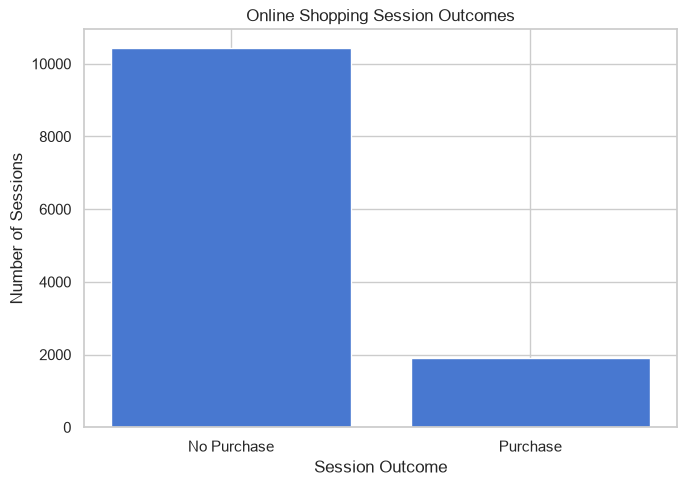

In [19]:
conversion_counts = df_features["Revenue"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Purchase", "Purchase"],
    [conversion_counts[False], conversion_counts[True]]
)

plt.title("Online Shopping Session Outcomes")
plt.xlabel("Session Outcome")
plt.ylabel("Number of Sessions")
plt.show()

## Conversion Rate
Approximately 15.5% of the shopping sessions resulted in a purchase, while about 84.5% did not. This indicates that purchases represent the minority outcome in the dataset. This class imbalance should be considered when evaluating predictive models.

In [20]:
df_features.groupby("Revenue")["TotalPages"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,31.284206,42.693917,0.0,7.0,18.0,38.0,746.0
True,1908.0,52.389937,60.417191,1.0,17.0,32.0,62.0,543.0


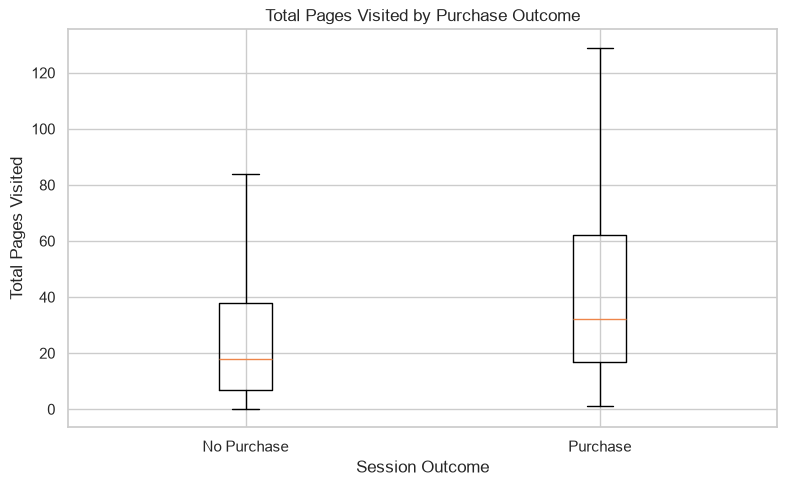

In [21]:
purchase_pages = df_features.loc[
    df_features["Revenue"] == True, "TotalPages"
]

nonpurchase_pages = df_features.loc[
    df_features["Revenue"] == False, "TotalPages"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [nonpurchase_pages, purchase_pages],
    tick_labels=["No Purchase", "Purchase"],
    showfliers=False
)

plt.title("Total Pages Visited by Purchase Outcome")
plt.xlabel("Session Outcome")
plt.ylabel("Total Pages Visited")
plt.show()

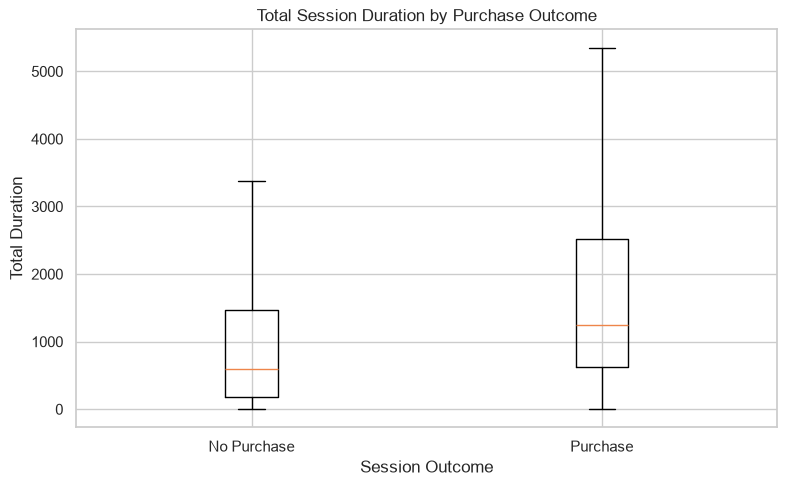

In [22]:
purchase_duration = df_features.loc[
    df_features["Revenue"] == True, "TotalDuration"
]

nonpurchase_duration = df_features.loc[
    df_features["Revenue"] == False, "TotalDuration"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [nonpurchase_duration, purchase_duration],
    tick_labels=["No Purchase", "Purchase"],
    showfliers=False
)

plt.title("Total Session Duration by Purchase Outcome")
plt.xlabel("Session Outcome")
plt.ylabel("Total Duration")
plt.show()

## Pages Visited and Purchase Behavior
Sessions that resulted in a purchase showed greater browsing activity than sessions that did not. Purchasing sessions visited an average of approximately 52 pages compared with 31 pages for non-purchasing sessions. The median was also higher for purchasing sessions (32 pages versus 18 pages), suggesting that greater website engagement may be associated with conversion.

In [23]:
df_features.groupby("Revenue")["TotalDuration"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,1173.964158,1925.426959,0.0,183.666667,588.166667,1464.005253,69921.647230
True,1908.0,2053.304285,2436.111519,0.0,620.358974,1252.075000,2513.856331,28450.201097


In [24]:
df_features.groupby("Revenue")["AvgDurationPerPage"].describe()

,count,mean,std,min,25%,50%,75%,max
Revenue,,,,,,,,
False,10422.0,37.016487,45.794450,0.0,17.040550,28.298458,44.250039,1411.0
True,1908.0,42.028320,26.605448,0.0,25.404241,36.259873,50.754527,354.0


In [25]:
visitor_conversion = (
    df_features.groupby("VisitorType")["Revenue"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

visitor_conversion["ConversionRate"] = visitor_conversion["mean"] * 100

visitor_conversion

,count,mean,ConversionRate
VisitorType,,,
New_Visitor,1694,0.249115,24.911452
Other,85,0.188235,18.823529
Returning_Visitor,10551,0.139323,13.932329


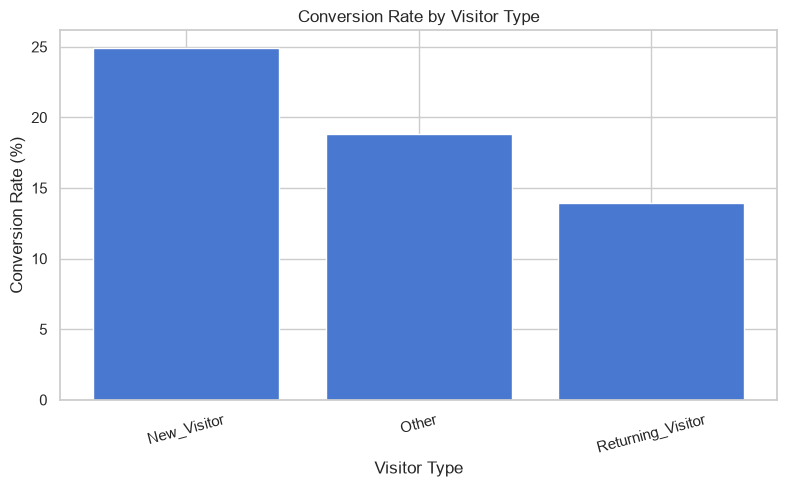

In [26]:
visitor_rates = (
    df_features.groupby("VisitorType")["Revenue"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
plt.bar(visitor_rates.index, visitor_rates.values)

plt.title("Conversion Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=15)
plt.show()

In [27]:
month_conversion = (
    df_features.groupby("Month")["Revenue"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

month_conversion

Month
Nov     25.350233
Oct     20.947177
Sep     19.196429
Aug     17.551963
Jul     15.277778
Dec     12.507238
May     10.850178
June    10.069444
Mar     10.068170
Feb      1.630435
Name: Revenue, dtype: float64

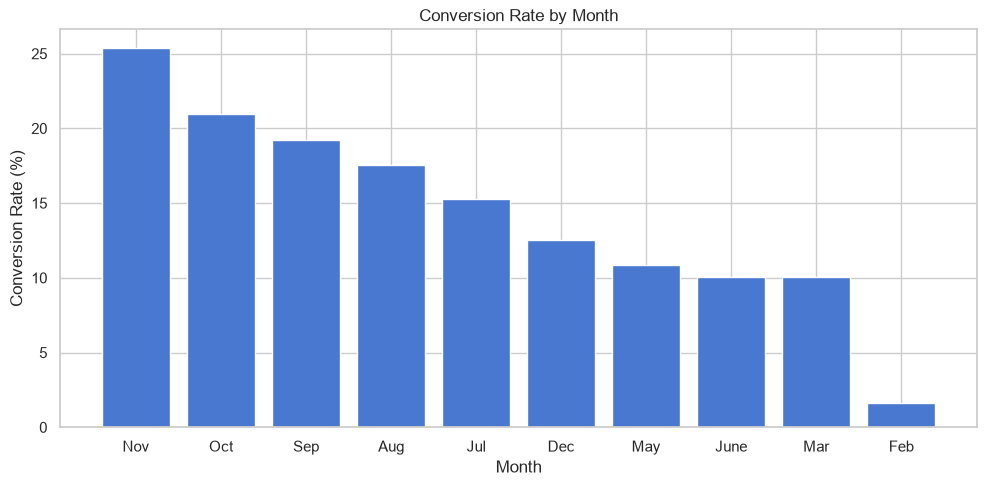

In [28]:
plt.figure(figsize=(10, 5))
plt.bar(month_conversion.index, month_conversion.values)

plt.title("Conversion Rate by Month")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.show()

## Session Duration and Purchase Behavior
Sessions that resulted in a purchase also tended to last longer. The median total session duration was approximately 1,252 seconds for purchasing sessions compared with 588 seconds for non-purchasing sessions. This suggests that greater overall engagement with the website may be associated with conversion.

## Average Time per Page
Purchasing sessions also spent somewhat more time per page than non-purchasing sessions. However, the difference is smaller than the differences observed for total pages visited and total session duration. This may indicate that overall engagement is more informative than time spent on an individual page.

## Conversion by Visitor Type
New visitors had the highest observed conversion rate at approximately 24.9%, compared with 13.9% for returning visitors. This suggests that visitor type may contain useful information for predicting purchase behavior. The "Other" visitor category contains relatively few observations, so its conversion rate should be interpreted cautiously.

## Conversion by Month
Conversion rates varied considerably by month. November had the highest observed conversion rate at approximately 25.4%, followed by October and September. This suggests that seasonality may be an important factor in online purchasing behavior.

In [29]:
weekend_conversion = (
    df_features.groupby("Weekend")["Revenue"]
    .agg(["count", "mean"])
)

weekend_conversion["ConversionRate"] = (
    weekend_conversion["mean"] * 100
)

weekend_conversion

,count,mean,ConversionRate
Weekend,,,
False,9462,0.148911,14.891144
True,2868,0.173989,17.398884


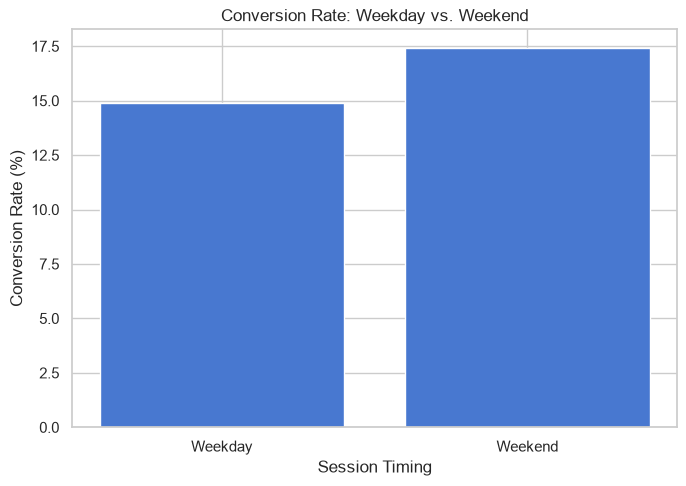

In [30]:
weekend_rates = (
    df_features.groupby("Weekend")["Revenue"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(7, 5))
plt.bar(
    ["Weekday", "Weekend"],
    [weekend_rates[False], weekend_rates[True]]
)

plt.title("Conversion Rate: Weekday vs. Weekend")
plt.xlabel("Session Timing")
plt.ylabel("Conversion Rate (%)")
plt.show()

## Conversion by Session Timing
Weekend sessions had a conversion rate of approximately 17.4%, compared with 14.9% for weekday sessions. This suggests that session timing may provide some predictive information, although the difference is relatively modest.

# Online Shopper Conversion Prediction
## 1. Modeling Objective
The goal of this analysis is to predict whether an online shopping session will result in a purchase using the Online Shoppers Purchasing Intention dataset.

Several classification models will be trained and compared to identify a model that can distinguish purchasing sessions from non-purchasing sessions. Model evaluation will emphasize precision, recall, F1-score, ROC-AUC, and the confusion matrix because the target classes are imbalanced.

The training set will be used to fit models, the validation set will support model comparison and hyperparameter tuning, and the test set will be reserved for final evaluation.

In [31]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [32]:
# load datasets, adjust path as needed
possible_paths = [
    Path("data/online_shoppers_intention.csv"),
    Path(r"C:\Users\tlsun\OneDrive\Desktop\USD Assignment\Applied Data Science for Business\Final Project 505\online_shoppers_intention.csv"),
    Path.home() / "Downloads" / "online_shoppers_intention.csv",
]

csv_path = next(
    (path for path in possible_paths if path.exists()),
    None,
)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find online_shoppers_intention.csv. "
        "Place it in the project's data folder or your Downloads folder."
    )

df = pd.read_csv(csv_path)

print(f"Loaded dataset from: {csv_path.resolve()}")
print(f"Dataset shape: {df.shape}")
display(df.head())

Loaded dataset from: C:\Users\tlsun\OneDrive\Desktop\USD Assignment\Applied Data Science for Business\Final Project 505\online_shoppers_intention.csv
Dataset shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [33]:
print("Target distribution:")
display(
    df["Revenue"]
    .value_counts()
    .rename(index={False: "No Purchase", True: "Purchase"})
    .to_frame("Count")
)

print("\nTarget proportions:")
display(
    (
        df["Revenue"]
        .value_counts(normalize=True)
        .mul(100)
        .rename(index={False: "No Purchase", True: "Purchase"})
        .to_frame("Percentage")
        .round(2)
    )
)

Target distribution:


,Count
Revenue,
No Purchase,10422
Purchase,1908



Target proportions:


,Percentage
Revenue,
No Purchase,84.53
Purchase,15.47


## 2. Feature Engineering and Preprocessing
Three engagement features are created from the original session variables: total pages visited, total session duration, and average duration per page. The data is split into training, validation, and test sets using stratified sampling to preserve the purchase rate.

Numerical features are imputed and standardized, while categorical features are imputed and one-hot encoded. Preprocessing is fitted only on the training set to reduce data leakage.

In [34]:
# Create engineered features and define the target
# Create a working copy
model_df = df.copy()

# Engineer engagement features
model_df["TotalPages"] = (
    model_df["Administrative"]
    + model_df["Informational"]
    + model_df["ProductRelated"]
)

model_df["TotalDuration"] = (
    model_df["Administrative_Duration"]
    + model_df["Informational_Duration"]
    + model_df["ProductRelated_Duration"]
)

model_df["AvgDurationPerPage"] = (
    model_df["TotalDuration"]
    / model_df["TotalPages"].replace(0, 1)
)

# Define target and predictors
X = model_df.drop(columns="Revenue")
y = model_df["Revenue"].astype(int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nEngineered features:")
display(
    model_df[
        ["TotalPages", "TotalDuration", "AvgDurationPerPage"]
    ].describe().round(2)
)

Feature matrix shape: (12330, 20)
Target shape: (12330,)

Engineered features:


,TotalPages,TotalDuration,AvgDurationPerPage
count,12330.00,12330.00,12330.00
mean,34.55,1310.04,37.79
std,46.51,2037.80,43.42
min,0.00,0.00,0.00
25%,8.00,222.00,18.23
50%,20.00,680.00,29.69
75%,42.00,1626.91,45.42
max,746.00,69921.65,1411.00


In [35]:
# Split into training, validation, and test sets
from sklearn.model_selection import train_test_split

# First, set aside 15% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Split the remaining data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1765,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

print("Training set:", X_train.shape, f"({len(X_train) / len(X):.1%})")
print("Validation set:", X_val.shape, f"({len(X_val) / len(X):.1%})")
print("Test set:", X_test.shape, f"({len(X_test) / len(X):.1%})")

print("\nPurchase rate by split:")
print(f"Training:   {y_train.mean():.2%}")
print(f"Validation: {y_val.mean():.2%}")
print(f"Test:       {y_test.mean():.2%}")


Training set: (8630, 20) (70.0%)
Validation set: (1850, 20) (15.0%)
Test set: (1850, 20) (15.0%)

Purchase rate by split:
Training:   15.48%
Validation: 15.46%
Test:       15.46%


In [36]:
# Define preprocessing

# Numerical features
numeric_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay",
    "TotalPages",
    "TotalDuration",
    "AvgDurationPerPage",
]

# Categorical features
categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
]

# Preprocess numerical and categorical variables separately
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ]
)

# Fit only on training data
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)

print("Processed training shape:", X_train_prep.shape)
print("Processed validation shape:", X_val_prep.shape)
print("Processed test shape:", X_test_prep.shape)


Processed training shape: (8630, 77)
Processed validation shape: (1850, 77)
Processed test shape: (1850, 77)


In [37]:
# Verify the prepared data
print("Missing values in original predictors:", X.isna().sum().sum())
print("Training target classes:", np.bincount(y_train))
print("Validation target classes:", np.bincount(y_val))
print("Test target classes:", np.bincount(y_test))

assert X_train_prep.shape[0] == len(y_train)
assert X_val_prep.shape[0] == len(y_val)
assert X_test_prep.shape[0] == len(y_test)

print("\nPreprocessing completed successfully.")

Missing values in original predictors: 0
Training target classes: [7294 1336]
Validation target classes: [1564  286]
Test target classes: [1564  286]

Preprocessing completed successfully.


## 3. Model Training and Comparison
Four classification models are evaluated using the training and validation sets. Performance is compared using accuracy, precision, recall, F1-score, and ROC-AUC. Since purchase sessions represent a minority of observations, particular attention is given to identifying actual purchase sessions rather than maximizing accuracy alone.

In [38]:
# Convert sparse matrices to dense arrays if needed
if hasattr(X_train_prep, "toarray"):
    X_train_prep = X_train_prep.toarray()
    X_val_prep = X_val_prep.toarray()
    X_test_prep = X_test_prep.toarray()

print("Training data shape:", X_train_prep.shape)
print("Data type:", type(X_train_prep))


# Train the model
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
}

validation_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_prep, y_train)

    y_pred = model.predict(X_val_prep)
    y_prob = model.predict_proba(X_val_prep)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
    })

    trained_models[name] = model

validation_results_df = (
    pd.DataFrame(validation_results)
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

display(validation_results_df.round(4))


Training data shape: (8630, 77)
Data type: <class 'numpy.ndarray'>


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Gradient Boosting,0.8941,0.7143,0.5245,0.6048,0.9263
1,Random Forest,0.8968,0.7844,0.4580,0.5784,0.9165
2,Decision Tree,0.8611,0.5495,0.5629,0.5561,0.7393
3,Logistic Regression,0.8822,0.7361,0.3706,0.4930,0.8903


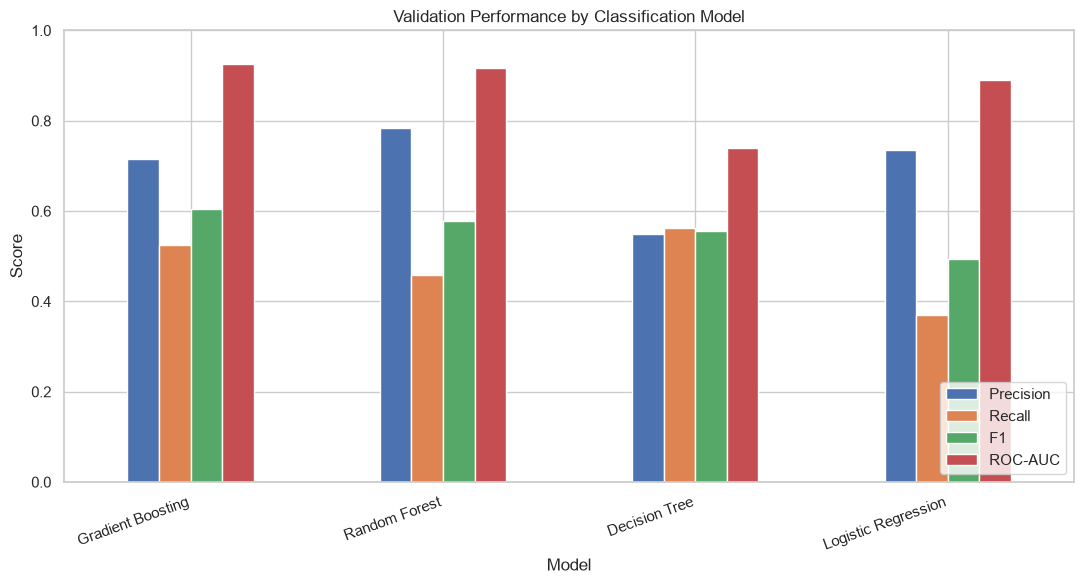

In [39]:
# Visualize the comparison

metrics_to_plot = ["Precision", "Recall", "F1", "ROC-AUC"]

validation_results_df.set_index("Model")[
    metrics_to_plot
].plot(kind="bar", figsize=(11, 6), ylim=(0, 1))

plt.title("Validation Performance by Classification Model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Hyperparameter Tuning/ Gradient Boosting
Gradient Boosting achieved the best validation F1 score and ROC-AUC in the initial model comparison. Grid search will be used to evaluate different hyperparameter combinations and identify a model that improves the balance between precision and recall. The test set will remain untouched until final model evaluation.

In [40]:
from sklearn.model_selection import GridSearchCV

gb_model = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE
)

param_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 200],
    "max_leaf_nodes": [15, 31],
    "l2_regularization": [0.0, 1.0],
}

grid_search = GridSearchCV(
    estimator=gb_model,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train_prep, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 15}
Best cross-validation F1: 0.6772


In [41]:
#Tune Gradient Boosting
param_grid = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [100, 200],
    "max_leaf_nodes": [15, 31],
}

grid_search = GridSearchCV(
    estimator=HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
)

grid_search.fit(X_train_prep, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Best parameters: {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 15}
Best cross-validation F1: 0.6753


In [42]:
best_model = grid_search.best_estimator_

y_val_pred = best_model.predict(X_val_prep)
y_val_prob = best_model.predict_proba(X_val_prep)[:, 1]

print("Validation Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Validation Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Validation Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("Validation F1:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

Validation Accuracy: 0.9027
Validation Precision: 0.7524
Validation Recall: 0.5524
Validation F1: 0.6371
Validation ROC-AUC: 0.9332


## 5. Final Test Set Evaluation
The tuned Gradient Boosting model is evaluated on the held-out test set to estimate its performance on unseen data. The test set was not used for model training or hyperparameter tuning.

In [43]:
best_model = grid_search.best_estimator_

y_test_pred = best_model.predict(X_test_prep)
y_test_prob = best_model.predict_proba(X_test_prep)[:, 1]

test_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
}])

display(test_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
0,0.9022,0.7215,0.5979,0.6539,0.936


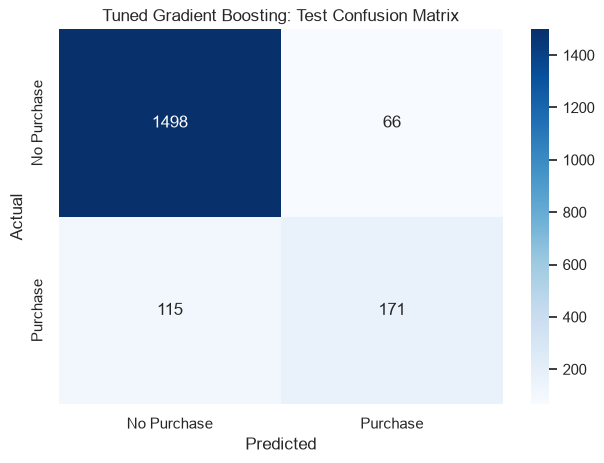

              precision    recall  f1-score   support

 No Purchase       0.93      0.96      0.94      1564
    Purchase       0.72      0.60      0.65       286

    accuracy                           0.90      1850
   macro avg       0.83      0.78      0.80      1850
weighted avg       0.90      0.90      0.90      1850



In [44]:
# Confusion matrix and classification report
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"],
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Gradient Boosting: Test Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Purchase", "Purchase"],
    zero_division=0,
))

The tuned Gradient Boosting model achieved 90.22% accuracy, 72.15% precision, 59.79% recall, an F1 score of 0.6539, and a ROC-AUC of 0.9360 on the test set. The model correctly identified 60% of actual purchasing sessions, while approximately 72% of its predicted purchases were correct. Performance was stronger for non-purchasing sessions, with 96% recall, reflecting the imbalance in the dataset. The results suggest that the model can help identify potential purchasers, although it still misses some sessions that result in purchases.

## 6. Feature Importance


,Feature,Importance
8,num__PageValues,0.4636
7,num__ExitRates,0.0482
20,cat__Month_Nov,0.0455
1,num__Administrative_Duration,0.0132
0,num__Administrative,0.0121
10,num__TotalPages,0.0117
19,cat__Month_May,0.0079
4,num__ProductRelated,0.0072
52,cat__Region_9,0.0072
14,cat__Month_Dec,0.0071


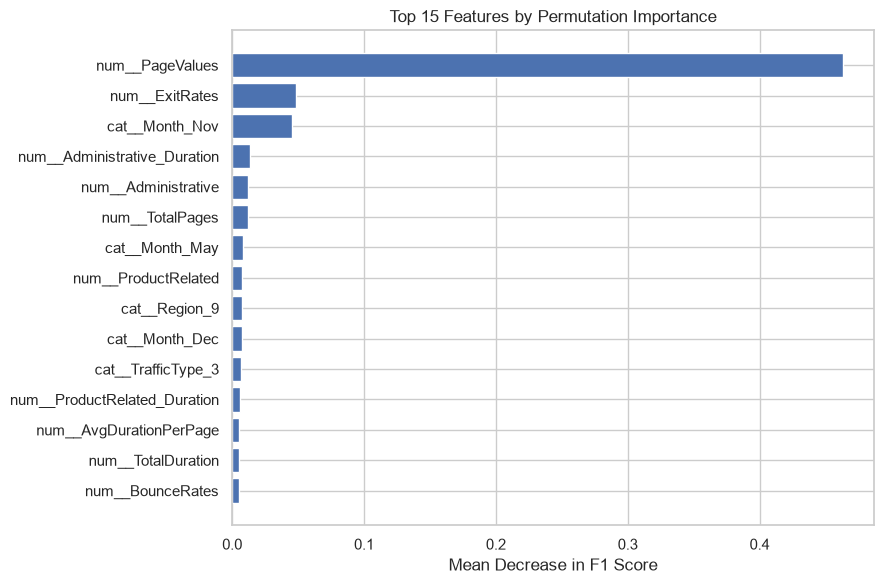

In [45]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_val_prep,
    y_val,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance.importances_mean,
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(4))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Mean Decrease in F1 Score")
plt.title("Top 15 Features by Permutation Importance")
plt.tight_layout()
plt.show()

Permutation importance identified PageValues as the most influential feature, with an importance score of 0.4636, substantially higher than the other features. ExitRates was the second most important feature at 0.0482, followed by the November indicator at 0.0455. Administrative activity, total pages viewed, and product-related activity also contributed to model performance, although their individual importance scores were much smaller.

These results suggest that page-value information and browsing behavior are particularly useful for predicting whether a session results in a purchase. However, feature importance indicates predictive usefulness, not causation. The strong importance of PageValues should also be interpreted in the context of how this variable is defined in the dataset.